# multiPI-TransBTS: reproduction on Google Colab

Paper: *multiPI-TransBTS: A Multi-Path Learning Framework for Brain Tumor Image Segmentation Based on Multi-Physical Information* (arXiv:2409.12167).
Official code: https://github.com/JoetheReindeer/multiPI_TransBTS

This notebook
1. checks the released code without any data (split lists, Hausdorff metric, model size),
2. downloads BraTS2020 and preprocesses it exactly as the released code does,
3. trains the released model with the released settings (baseline),
4. trains the proposed variant (one changed parameter: the false-negative weight of the ET loss),
5. reports both the released metrics and standard metrics, on the official test slices and on patients never seen in training.

**Runtime → Change runtime type → T4 GPU** before running. Run the cells top to bottom.

In [ ]:
# ---------------- configuration ----------------
PRESET = "scaled"   # "scaled": fits one free Colab T4 session.  "full": the paper's setting (all 369 patients, 100 epochs).

if PRESET == "scaled":
    N_SUBSET  = 80    # patients the official split lists are restricted to
    N_HELDOUT = 30    # further patients kept completely out of training (unseen-patient test)
    EPOCHS    = 15    # upper limit; reduced automatically in section 3 to fit TRAIN_MINUTES_PER_RUN
    TRAIN_MINUTES_PER_RUN = 25
else:
    N_SUBSET, N_HELDOUT, EPOCHS, TRAIN_MINUTES_PER_RUN = None, 0, 100, None

ET_BETA_VARIANT = 0.7   # proposed change; 0.5 reproduces the released Dice loss
SEED = 0
BATCH_SIZE = 12         # as in the paper

In [ ]:
%%writefile /content/repro.patch
diff --git a/.gitignore b/.gitignore
new file mode 100644
index 0000000..30677d8
--- /dev/null
+++ b/.gitignore
@@ -0,0 +1,8 @@
+__pycache__/
+*.pyc
+networks/pretrained_pth/*.pth
+/prep/
+/raw/
+checkpoint.pt
+*.ckpt
+.ipynb_checkpoints/
diff --git a/kits/losses.py b/kits/losses.py
index 3d58de5..7bf8e76 100644
--- a/kits/losses.py
+++ b/kits/losses.py
@@ -24,7 +24,7 @@ class BinaryCrossEntropy(torch.nn.Module):
         loss = 0
         # target = torch.unsqueeze(target, 1)
         n, c, h, w = output.size()
-        criterion = torch.nn.BCELoss(weight=weight, reduction='mean').cuda()
+        criterion = torch.nn.BCELoss(weight=weight, reduction='mean')
         loss = criterion(output, target.float())
         loss /= n
         '''
diff --git a/networks/pvt_new.py b/networks/pvt_new.py
index e2a2225..56a1844 100644
--- a/networks/pvt_new.py
+++ b/networks/pvt_new.py
@@ -10,7 +10,8 @@ class Curvature(torch.nn.Module):
     def __init__(self, ratio):
         super(Curvature, self).__init__()
         weights = torch.tensor([[[[-1 / 16, 5 / 16, -1 / 16], [5 / 16, -1, 5 / 16], [-1 / 16, 5 / 16, -1 / 16]]]])
-        self.weight = torch.nn.Parameter(weights).cuda()
+        # fixed (non-learned) curvature kernel; a buffer follows the module's device
+        self.register_buffer('weight', weights, persistent=False)
         self.ratio = ratio

     def forward(self, x):
@@ -184,7 +185,7 @@ class Final_Up(nn.Module):


 class multiPI_TransBTS(nn.Module):
-    def __init__(self, ratio):
+    def __init__(self, ratio, pretrained_path='./networks/pretrained_pth/pvt_v2_b2.pth'):
         super(multiPI_TransBTS, self).__init__()
         self.conv1 = nn.Conv2d(in_channels=1, out_channels=3, kernel_size=3, padding=1)
         self.conv2 = nn.Conv2d(in_channels=1, out_channels=3, kernel_size=3, padding=1)
@@ -194,8 +195,7 @@ class multiPI_TransBTS(nn.Module):
         self.backbone3 = pvt_v2_b2()  # [64, 128, 320, 512]
         self.backbone4 = pvt_v2_b2()  # [64, 128, 320, 512]

-        path = './networks/pretrained_pth/pvt_v2_b2.pth'
-        save_model = torch.load(path)
+        save_model = torch.load(pretrained_path, map_location='cpu')
         model_dict = self.backbone1.state_dict()
         state_dict = {k: v for k, v in save_model.items() if k in model_dict.keys()}
         model_dict.update(state_dict)
diff --git a/repro/__init__.py b/repro/__init__.py
new file mode 100644
index 0000000..e69de29
diff --git a/repro/audit.py b/repro/audit.py
new file mode 100644
index 0000000..7588e18
--- /dev/null
+++ b/repro/audit.py
@@ -0,0 +1,110 @@
+"""Checks of the released code that need no dataset and no GPU.
+
+    python -m repro.audit            # prints the findings and writes results/audit.json
+
+1. Split: are the official train / val / test lists disjoint at patient level?
+2. Hausdorff: what does kits.metrics.hausdorff_95 return for masks whose true
+   distance is known?
+3. Model: parameter count, and parameters that never receive a gradient.
+"""
+import argparse
+import json
+import os
+
+import numpy as np
+
+from repro import data as D
+from repro.metrics import hd95
+
+
+def split_audit(repo_root, year):
+    lists = D.official_lists(repo_root, year)
+    pats = {k: {D.patient_of(n) for n in v} for k, v in lists.items()}
+    n_all = sum(len(v) for v in lists.values())
+    return {
+        "slices": {k: len(v) for k, v in lists.items()},
+        "slice_fraction": {k: round(len(v) / n_all, 4) for k, v in lists.items()},
+        "patients_total": len(set().union(*pats.values())),
+        "patients": {k: len(v) for k, v in pats.items()},
+        "slice_overlap_train_test": len(set(lists["train"]) & set(lists["test"])),
+        "test_patients_also_in_train": len(pats["test"] & pats["train"]),
+        "val_patients_also_in_train": len(pats["val"] & pats["train"]),
+        "test_patients_also_in_val": len(pats["test"] & pats["val"]),
+    }
+
+
+def neighbour_audit(repo_root, year):
+    """For each test slice: is the slice directly above or below it (same patient) in train?"""
+    lists = D.official_lists(repo_root, year)
+    train = set(lists["train"])
+    hits = 0
+    for n in lists["test"]:
+        p, s = D.patient_of(n), D.slice_of(n)
+        if f"{p}_{s - 1}" in train or f"{p}_{s + 1}" in train:
+            hits += 1
+    return {"test_slices": len(lists["test"]), "with_adjacent_slice_in_train": hits,
+            "fraction": round(hits / len(lists["test"]), 4)}
+
+
+def hausdorff_audit():
+    from kits import metrics as official
+    yy, xx = np.mgrid[:224, :224]
+
+    def disc(cx, cy=112, r=20):
+        return ((yy - cy) ** 2 + (xx - cx) ** 2 < r ** 2).astype(np.int64)
+
+    ref = disc(60)
+    rows = []
+    for shift in (0, 5, 30, 60, 90):
+        moved = disc(60 + shift)
+        rows.append({
+            "shift_px": shift,
+            "released_hausdorff_95": round(float(official.hausdorff_95(moved[None], ref[None])), 3),
+            "spatial_hd95_px": round(hd95(moved, ref), 3),
+        })
+    return rows
+
+
+def model_audit(pretrained):
+    import torch
+    from networks.pvt_new import multiPI_TransBTS
+    model = multiPI_TransBTS([0.5, 0.5], pretrained_path=pretrained)
+    out = model(torch.rand(1, 4, 224, 224))
+    sum(o.mean() for o in out[1:]).backward()
+    total = sum(p.numel() for p in model.parameters())
+    unused = {}
+    for k, p in model.named_parameters():
+        if p.grad is None:
+            top = ".".join(k.split(".")[:2]) if k.startswith("backbone0") else k.split(".")[0]
+            unused[top] = unused.get(top, 0) + p.numel()
+    return {"params_million": round(total / 1e6, 2),
+            "never_used_million": round(sum(unused.values()) / 1e6, 2),
+            "never_used_modules": {k: round(v / 1e6, 2) for k, v in sorted(unused.items())}}
+
+
+def main(argv=None):
+    p = argparse.ArgumentParser()
+    p.add_argument("--repo_root", default=".")
+    p.add_argument("--pretrained", default="./networks/pretrained_pth/pvt_v2_b2.pth")
+    p.add_argument("--out", default="results/audit.json")
+    args = p.parse_args(argv)
+    res = {"split": {}, "adjacent": {}}
+    for year in ("2019", "2020"):
+        res["split"][year] = split_audit(args.repo_root, year)
+        res["adjacent"][year] = neighbour_audit(args.repo_root, year)
+    res["hausdorff"] = hausdorff_audit()
+    if os.path.exists(args.pretrained):
+        res["model"] = model_audit(args.pretrained)
+    os.makedirs(os.path.dirname(args.out) or ".", exist_ok=True)
+    with open(args.out, "w") as f:
+        json.dump(res, f, indent=2)
+    print(json.dumps(res, indent=2))
+    try:
+        from repro.make_report import hausdorff_figure
+        hausdorff_figure(args.out, os.path.join(os.path.dirname(args.out) or ".", "figures"))
+    except ImportError:  # matplotlib missing: the JSON is still complete
+        pass
+
+
+if __name__ == "__main__":
+    main()
diff --git a/repro/build_notebook.py b/repro/build_notebook.py
new file mode 100644
index 0000000..c3a0fce
--- /dev/null
+++ b/repro/build_notebook.py
@@ -0,0 +1,174 @@
+"""Writes notebooks/multiPI_TransBTS_colab.ipynb (kept as code so the notebook is reviewable)."""
+import json
+import sys
+
+REPO_URL = sys.argv[1] if len(sys.argv) > 1 else "https://github.com/YOUR_USER/multiPI_TransBTS.git"
+BRANCH = sys.argv[2] if len(sys.argv) > 2 else "reproduction"
+OUT = sys.argv[3] if len(sys.argv) > 3 else "notebooks/multiPI_TransBTS_colab.ipynb"
+PATCH = open(sys.argv[4]).read() if len(sys.argv) > 4 else None  # standalone flavour: upstream + patch
+
+cells = []
+
+
+def md(text):
+    cells.append({"cell_type": "markdown", "metadata": {}, "source": text.strip("\n").splitlines(True)})
+
+
+def code(text):
+    cells.append({"cell_type": "code", "metadata": {}, "execution_count": None, "outputs": [],
+                  "source": text.strip("\n").splitlines(True)})
+
+
+md("""
+# multiPI-TransBTS: reproduction on Google Colab
+
+Paper: *multiPI-TransBTS: A Multi-Path Learning Framework for Brain Tumor Image Segmentation Based on Multi-Physical Information* (arXiv:2409.12167).
+Official code: https://github.com/JoetheReindeer/multiPI_TransBTS
+
+This notebook
+1. checks the released code without any data (split lists, Hausdorff metric, model size),
+2. downloads BraTS2020 and preprocesses it exactly as the released code does,
+3. trains the released model with the released settings (baseline),
+4. trains the proposed variant (one changed parameter: the false-negative weight of the ET loss),
+5. reports both the released metrics and standard metrics, on the official test slices and on patients never seen in training.
+
+**Runtime → Change runtime type → T4 GPU** before running. Run the cells top to bottom.
+""")
+
+code("""
+# ---------------- configuration ----------------
+PRESET = "scaled"   # "scaled": fits one free Colab T4 session.  "full": the paper's setting (all 369 patients, 100 epochs).
+
+if PRESET == "scaled":
+    N_SUBSET  = 80    # patients the official split lists are restricted to
+    N_HELDOUT = 30    # further patients kept completely out of training (unseen-patient test)
+    EPOCHS    = 15    # upper limit; reduced automatically in section 3 to fit TRAIN_MINUTES_PER_RUN
+    TRAIN_MINUTES_PER_RUN = 70
+else:
+    N_SUBSET, N_HELDOUT, EPOCHS, TRAIN_MINUTES_PER_RUN = None, 0, 100, None
+
+ET_BETA_VARIANT = 0.7   # proposed change; 0.5 reproduces the released Dice loss
+SEED = 0
+BATCH_SIZE = 12         # as in the paper
+""")
+
+if PATCH is None:
+    code(f"""
+!nvidia-smi --query-gpu=name,memory.total --format=csv
+%cd /content
+!rm -rf multiPI_TransBTS && git clone -q -b {BRANCH} {REPO_URL} multiPI_TransBTS
+%cd /content/multiPI_TransBTS
+!pip install -q -r requirements-colab.txt
+!mkdir -p networks/pretrained_pth && wget -q -nc -O networks/pretrained_pth/pvt_v2_b2.pth https://github.com/whai362/PVT/releases/download/v2/pvt_v2_b2.pth
+!git log --oneline | head -5
+""")
+else:
+    code("%%writefile /content/repro.patch\n" + PATCH)
+    code("""
+!nvidia-smi --query-gpu=name,memory.total --format=csv
+%cd /content
+!rm -rf multiPI_TransBTS && git clone -q https://github.com/JoetheReindeer/multiPI_TransBTS.git multiPI_TransBTS
+%cd /content/multiPI_TransBTS
+!echo >> /content/repro.patch
+!git checkout -q 6ef9eee && git apply --whitespace=nowarn /content/repro.patch && git status --short | head -20
+!pip install -q -r requirements-colab.txt
+!mkdir -p networks/pretrained_pth && wget -q -nc -O networks/pretrained_pth/pvt_v2_b2.pth https://github.com/whai362/PVT/releases/download/v2/pvt_v2_b2.pth
+""")
+
+md("""
+## 1. Checks that need no data
+Patient overlap between the official train/val/test lists, what the released `hausdorff_95` returns for masks with a known distance, and the model's parameter count.
+""")
+code("!python -W ignore -m repro.audit --out results/audit.json")
+
+md("""
+## 2. Data
+BraTS2020 training set from the public Kaggle mirror `awsaf49/brats20-dataset-training-validation` (about 4 GB).
+If the anonymous download is refused, add your Kaggle API token as Colab secrets `KAGGLE_USERNAME` / `KAGGLE_KEY` (key icon in the left bar) and re-run.
+""")
+code("""
+import kagglehub, os
+RAW = kagglehub.dataset_download("awsaf49/brats20-dataset-training-validation")
+print(RAW); print(os.listdir(RAW))
+""")
+code("""
+sub = f"--n_subset {N_SUBSET} --n_heldout {N_HELDOUT}" if N_SUBSET else ""
+!python -W ignore -m repro.prepare_data --raw "{RAW}" --out /content/prep {sub} --seed {SEED}
+""")
+
+md("""
+## 3. Speed check
+40 training iterations with the real batch size, to measure iterations per second and peak GPU memory before committing to a run.
+If batch 12 does not fit in GPU memory, the batch size is reduced (this would be a deviation from the paper and is recorded in the results).
+In the scaled preset the number of epochs is then set so that one run fits in `TRAIN_MINUTES_PER_RUN`.
+""")
+code("""
+import json, subprocess, sys
+for bs in (BATCH_SIZE, 8, 6, 4):
+    cmd = f"{sys.executable} -W ignore -m repro.train --prep_dir /content/prep --out /content/bench {sub} --seed {SEED} --batch_size {bs} --epochs 1 --amp --max_train_iters 40 --no_eval"
+    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
+    print(r.stdout[-1500:])
+    if r.returncode == 0:
+        BATCH_SIZE = bs
+        break
+    print(f"batch size {bs} failed:", r.stderr[-600:])
+else:
+    raise RuntimeError("the model does not fit on this GPU even at batch size 4")
+
+b = json.load(open("/content/bench/results.json"))
+ips = b["history"][-1]["it_per_s"]
+print(f"batch size {BATCH_SIZE}: {ips:.2f} it/s on {b['device']}, peak GPU memory {b['peak_gpu_mem_gb']:.1f} GB, {b['iters_per_epoch']} iterations per epoch")
+print(f"the paper's full setting (1628 iterations x 100 epochs at batch 12) would take about {1628 * 100 * 12 / BATCH_SIZE / ips / 3600:.0f} GPU-hours on this GPU")
+if TRAIN_MINUTES_PER_RUN:
+    fit = int(TRAIN_MINUTES_PER_RUN * 60 * ips / b["iters_per_epoch"])
+    EPOCHS = max(3, min(EPOCHS, fit))
+print(f"epochs per run: {EPOCHS}  (about {b['iters_per_epoch'] * EPOCHS / ips / 60:.0f} min of training per run)")
+""")
+
+md("## 4. Baseline: released model, released settings")
+code("""
+!python -W ignore -m repro.train --prep_dir /content/prep --out results/baseline --ckpt_dir /content/ckpt_baseline {sub} --seed {SEED} --batch_size {BATCH_SIZE} --epochs {EPOCHS} --amp --et_beta 0.5
+""")
+
+md("""
+## 5. Proposed variant: ET loss with false-negative weight beta
+Everything is identical to the baseline (same split, seed, schedule) except `--et_beta`.
+""")
+code("""
+VAR = f"results/variant_et_beta{ET_BETA_VARIANT}"
+!python -W ignore -m repro.train --prep_dir /content/prep --out {VAR} --ckpt_dir /content/ckpt_variant {sub} --seed {SEED} --batch_size {BATCH_SIZE} --epochs {EPOCHS} --amp --et_beta {ET_BETA_VARIANT}
+""")
+
+md("## 6. Report")
+code("""
+!python -W ignore -m repro.make_report --baseline results/baseline --variant {VAR} --out results > /dev/null
+from IPython.display import Markdown, Image, display
+display(Markdown(open("results/summary.md").read()))
+for f in ("dice_protocols", "et_variant", "training_loss", "examples"):
+    if os.path.exists(f"results/figures/{f}.png"):
+        display(Image(f"results/figures/{f}.png", width=760))
+""")
+code("""
+# compact machine-readable dump of the numbers (for copying into the README / slides)
+import json
+for run in ("results/baseline", VAR):
+    r = json.load(open(f"{run}/results.json"))
+    keep = {k: r[k] for k in ("split", "test", "unseen", "device", "peak_gpu_mem_gb", "iters_per_epoch", "params_million") if k in r}
+    keep["history"] = [{k: (round(v, 4) if isinstance(v, float) else v) for k, v in h.items()} for h in r["history"]]
+    keep["config"] = {k: r["config"][k] for k in ("epochs", "batch_size", "n_subset", "n_heldout", "seed", "et_beta", "lr")}
+    print("RESULT_JSON", run, json.dumps(keep, separators=(",", ":")))
+""")
+code("""
+# download everything (results.json files, summary, figures, example arrays)
+!cd /content/multiPI_TransBTS && zip -q -r /content/results.zip results
+from google.colab import files
+files.download("/content/results.zip")
+""")
+
+nb = {"cells": cells, "metadata": {"accelerator": "GPU", "colab": {"provenance": [], "gpuType": "T4"},
+                                   "kernelspec": {"display_name": "Python 3", "name": "python3"},
+                                   "language_info": {"name": "python"}},
+      "nbformat": 4, "nbformat_minor": 0}
+with open(OUT, "w") as f:
+    json.dump(nb, f, indent=1)
+print("wrote", OUT, len(cells), "cells")
diff --git a/repro/data.py b/repro/data.py
new file mode 100644
index 0000000..242b7e5
--- /dev/null
+++ b/repro/data.py
@@ -0,0 +1,213 @@
+"""Data preparation and splits for the multiPI-TransBTS reproduction.
+
+The preprocessing follows data2020/dataset_preprocess.py from the official repo
+step for step (SimpleITK Int16 read, percentile clipping on the brain mask,
+division by the maximum, 224x224 centre crop, only slices that contain tumour,
+channel order FLAIR / T1 / T1ce / T2). The only differences are practical:
+one compressed file per patient instead of one .npy per slice, and float16
+storage instead of float64, so that a subset fits in Colab RAM.
+"""
+import glob
+import os
+
+import numpy as np
+
+MODALITIES = ("flair", "t1", "t1ce", "t2")  # channel order used by the official code
+CROP = 224
+
+
+# ----------------------------------------------------------------------------
+# official preprocessing (copied in behaviour from data2020/dataset_preprocess.py)
+# ----------------------------------------------------------------------------
+def normalize(image, percentile_lower=0.2, percentile_upper=99.8):
+    mask = image != image[0, 0, 0]
+    cut_off_lower = np.percentile(image[mask != 0].ravel(), percentile_lower)
+    cut_off_upper = np.percentile(image[mask != 0].ravel(), percentile_upper)
+    res = np.copy(image)
+    res[(res < cut_off_lower) & (mask != 0)] = cut_off_lower
+    res[(res > cut_off_upper) & (mask != 0)] = cut_off_upper
+    res = res / res.max()
+    return res
+
+
+def crop_center(vol, croph=CROP, cropw=CROP):
+    height, width = vol[0].shape
+    starth = height // 2 - (croph // 2)
+    startw = width // 2 - (cropw // 2)
+    return vol[:, starth:starth + croph, startw:startw + cropw]
+
+
+def _find_file(case_dir, case, suffix):
+    for ext in (".nii.gz", ".nii"):
+        p = os.path.join(case_dir, f"{case}_{suffix}{ext}")
+        if os.path.exists(p):
+            return p
+    if suffix == "seg":  # the Kaggle mirror ships one mis-named label file (case 355)
+        cand = [f for f in glob.glob(os.path.join(case_dir, "*"))
+                if "seg" in os.path.basename(f).lower()]
+        if cand:
+            return cand[0]
+    raise FileNotFoundError(f"{case}: no {suffix} volume in {case_dir}")
+
+
+def find_cases(raw_root):
+    """Return {case_name: case_dir} for every BraTS case folder below raw_root."""
+    cases = {}
+    for dirpath, _dirnames, filenames in os.walk(raw_root):
+        if any(f.endswith(("_flair.nii.gz", "_flair.nii")) for f in filenames):
+            name = os.path.basename(dirpath)
+            if any("seg" in f.lower() for f in filenames):  # labelled cases only
+                cases[name] = dirpath
+    return dict(sorted(cases.items()))
+
+
+def preprocess_case(case, case_dir, out_dir):
+    """Preprocess one patient; writes <out_dir>/<case>.npz and returns the slice count."""
+    import SimpleITK as sitk
+
+    out_path = os.path.join(out_dir, f"{case}.npz")
+    if os.path.exists(out_path):
+        with np.load(out_path) as z:
+            return int(z["slices"].shape[0])
+
+    vols = []
+    for mod in MODALITIES:
+        arr = sitk.GetArrayFromImage(sitk.ReadImage(_find_file(case_dir, case, mod), sitk.sitkInt16))
+        vols.append(crop_center(normalize(arr)))
+    seg = sitk.GetArrayFromImage(sitk.ReadImage(_find_file(case_dir, case, "seg"), sitk.sitkUInt8))
+    seg = crop_center(seg)
+
+    keep = [z for z in range(seg.shape[0]) if seg[z].max() != 0]
+    img = np.stack([v[keep] for v in vols], axis=1).astype(np.float16)  # (n, 4, 224, 224)
+    np.savez_compressed(out_path, img=img, mask=seg[keep].astype(np.uint8),
+                        slices=np.asarray(keep, dtype=np.int16))
+    return len(keep)
+
+
+# ----------------------------------------------------------------------------
+# splits
+# ----------------------------------------------------------------------------
+def read_name_list(path):
+    """The official lists mix \\n and bare \\r line endings."""
+    with open(path, "r", newline="") as f:
+        text = f.read()
+    return [x.strip() for x in text.replace("\r", "\n").split("\n") if x.strip()]
+
+
+def patient_of(slice_name):
+    return slice_name.rsplit("_", 1)[0]
+
+
+def slice_of(slice_name):
+    return int(slice_name.rsplit("_", 1)[1])
+
+
+def official_lists(repo_root, year="2020"):
+    d = os.path.join(repo_root, f"data{year}")
+    val_file = "val.txt" if year == "2020" else "val_list.txt"
+    return {
+        "train": read_name_list(os.path.join(d, "train_list.txt")),
+        "val": read_name_list(os.path.join(d, val_file)),
+        "test": read_name_list(os.path.join(d, "test_list.txt")),
+    }
+
+
+def choose_patients(all_patients, n_subset, n_heldout, seed=0):
+    """Deterministic choice of the experiment subset S and of unseen patients H.
+
+    S is the pool the official (slice-level) lists are restricted to.
+    H is disjoint from S and is never used for training in any protocol.
+    """
+    all_patients = sorted(all_patients)
+    rng = np.random.RandomState(seed)
+    perm = rng.permutation(len(all_patients))
+    if n_subset is None or n_subset + n_heldout >= len(all_patients):
+        # full run: nothing is left over for an unseen-patient set
+        return all_patients, []
+    subset = sorted(all_patients[i] for i in perm[:n_subset])
+    heldout = sorted(all_patients[i] for i in perm[n_subset:n_subset + n_heldout])
+    return subset, heldout
+
+
+def build_split(repo_root, subset, heldout, protocol="official", seed=0, year="2020"):
+    """Return {split_name: [slice names]}.
+
+    protocol="official": the official train/val/test slice lists, restricted to
+        the patients in `subset`. Slices of one patient land in all three splits.
+    protocol="patient":  the patients in `subset` are divided 8:1:1 and every
+        slice follows its patient.
+    In both cases "unseen" holds all official slices of the `heldout` patients.
+    """
+    lists = official_lists(repo_root, year)
+    every = lists["train"] + lists["val"] + lists["test"]
+    sub, held = set(subset), set(heldout)
+    split = {"unseen": sorted(n for n in every if patient_of(n) in held)}
+    if protocol == "official":
+        for k in ("train", "val", "test"):
+            split[k] = [n for n in lists[k] if patient_of(n) in sub]
+    elif protocol == "patient":
+        pts = sorted(sub)
+        rng = np.random.RandomState(seed + 1)
+        rng.shuffle(pts)
+        n_val = max(1, round(0.1 * len(pts)))
+        n_test = max(1, round(0.1 * len(pts)))
+        groups = {"val": set(pts[:n_val]), "test": set(pts[n_val:n_val + n_test]),
+                  "train": set(pts[n_val + n_test:])}
+        for k, g in groups.items():
+            split[k] = sorted(n for n in every if patient_of(n) in g)
+    else:
+        raise ValueError(protocol)
+    return split
+
+
+def leakage_report(split):
+    """How many patients of each evaluation split also occur in the training split."""
+    train_p = {patient_of(n) for n in split["train"]}
+    rep = {}
+    for k in ("val", "test", "unseen"):
+        p = {patient_of(n) for n in split.get(k, [])}
+        rep[k] = {"slices": len(split.get(k, [])), "patients": len(p),
+                  "patients_also_in_train": len(p & train_p)}
+    rep["train"] = {"slices": len(split["train"]), "patients": len(train_p)}
+    return rep
+
+
+# ----------------------------------------------------------------------------
+# in-memory dataset
+# ----------------------------------------------------------------------------
+class SliceStore:
+    """Loads the preprocessed patients needed for a split into RAM once."""
+
+    def __init__(self, prep_dir, patients):
+        self.index = {}
+        imgs, masks = [], []
+        offset = 0
+        for p in sorted(patients):
+            with np.load(os.path.join(prep_dir, f"{p}.npz")) as z:
+                img, mask, slices = z["img"], z["mask"], z["slices"]
+            imgs.append(img)
+            masks.append(mask)
+            for i, s in enumerate(slices):
+                self.index[f"{p}_{int(s)}"] = offset + i
+            offset += len(slices)
+        self.img = np.concatenate(imgs, axis=0)    # (N, 4, 224, 224) float16
+        self.mask = np.concatenate(masks, axis=0)  # (N, 224, 224) uint8, labels 0/1/2/4
+
+    def rows(self, names):
+        missing = [n for n in names if n not in self.index]
+        if missing:
+            raise KeyError(f"{len(missing)} slices from the split list were not produced by "
+                           f"preprocessing, e.g. {missing[:3]}")
+        return np.asarray([self.index[n] for n in names], dtype=np.int64)
+
+
+def region_targets(mask):
+    """BraTS labels -> (WT, TC, ET) binary maps, as in data2020/dataset_example.py.
+
+    mask: integer tensor (B, H, W) with labels 0, 1 (NCR/NET), 2 (ED), 4 (ET).
+    """
+    import torch
+    wt = mask > 0
+    tc = (mask == 1) | (mask == 4)
+    et = mask == 4
+    return torch.stack([wt, tc, et], dim=1).float()
diff --git a/repro/losses.py b/repro/losses.py
new file mode 100644
index 0000000..6b6ca5d
--- /dev/null
+++ b/repro/losses.py
@@ -0,0 +1,50 @@
+"""Training loss.
+
+`official_loss` reproduces trainer.py of the released code exactly:
+
+    per head k in {WT, TC, ET}:  L_k = Dice(p_k, y_k) + BCE(p_k, y_k) / batch_size
+    L = 0.3 * (L_WT + L_TC + L_ET)
+
+(The paper's Eq. 24 has unit weights and no division of BCE by the batch size;
+the released code is what produced the released numbers, so it is the baseline.)
+
+The proposed variant changes one thing: the overlap term of the ET head becomes a
+Tversky index with false-negative weight beta. With beta = 0.5 the Tversky index
+equals the Dice coefficient, so beta = 0.5 is the baseline and beta > 0.5 trades
+precision for sensitivity on the enhancing-tumour head only.
+"""
+import torch
+import torch.nn.functional as F
+
+EPS = 1e-7  # same constant as kits/losses.py::BinaryDiceLoss
+
+
+def tversky_loss(prob, target, beta=0.5):
+    """1 - mean_over_samples( TP / (TP + (1-beta) FP + beta FN) ).
+
+    For beta = 0.5 this is algebraically kits.losses.BinaryDiceLoss:
+        2 * sum(p*y) / (sum(p) + sum(y) + eps)
+    """
+    n = target.size(0)
+    p = prob.reshape(n, -1)
+    y = target.reshape(n, -1)
+    tp = (p * y).sum(1)
+    fp = (p * (1 - y)).sum(1)
+    fn = ((1 - p) * y).sum(1)
+    index = tp / (tp + (1 - beta) * fp + beta * fn + EPS / 2)
+    return 1 - index.sum() / n
+
+
+def official_loss(logit_wt, logit_tc, logit_et, target, et_beta=0.5, head_weight=0.3):
+    """target: (B, 3, H, W) float with channels WT, TC, ET."""
+    total = 0.0
+    parts = {}
+    for k, (name, logit) in enumerate((("WT", logit_wt), ("TC", logit_tc), ("ET", logit_et))):
+        prob = torch.sigmoid(logit.float())
+        y = target[:, k:k + 1]
+        beta = et_beta if name == "ET" else 0.5
+        overlap = tversky_loss(prob, y, beta)
+        bce = F.binary_cross_entropy(prob, y, reduction="mean") / prob.size(0)
+        parts[name] = (overlap + bce).detach()
+        total = total + head_weight * (overlap + bce)
+    return total, parts
diff --git a/repro/make_report.py b/repro/make_report.py
new file mode 100644
index 0000000..54f54e8
--- /dev/null
+++ b/repro/make_report.py
@@ -0,0 +1,245 @@
+"""Turn results/*/results.json into tables (results/summary.md) and figures.
+
+    python -m repro.make_report --baseline results/baseline --variant results/variant_et_beta0.7
+"""
+import argparse
+import json
+import os
+
+import numpy as np
+
+# "Ours" rows of Tables 2 and 3 of the paper (arXiv:2409.12167)
+PAPER = {
+    "2019": {"dice": {"WT": 0.953, "TC": 0.944, "ET": 0.904, "Mean": 0.934},
+             "hd95": {"WT": 2.177, "TC": 1.538, "ET": 1.334, "Mean": 1.683},
+             "sens": {"WT": 0.962, "TC": 0.954, "ET": 0.899, "Mean": 0.938}},
+    "2020": {"dice": {"WT": 0.954, "TC": 0.947, "ET": 0.909, "Mean": 0.937},
+             "hd95": {"WT": 2.167, "TC": 1.476, "ET": 1.271, "Mean": 1.638},
+             "sens": {"WT": 0.961, "TC": 0.951, "ET": 0.909, "Mean": 0.940}},
+}
+REGIONS = ("WT", "TC", "ET")
+BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
+INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
+
+
+def _style():
+    import matplotlib
+    matplotlib.use("Agg")
+    import matplotlib.pyplot as plt
+    plt.rcParams.update({
+        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
+        "font.size": 12, "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
+        "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
+        "axes.spines.right": False, "axes.spines.left": False, "axes.grid": True,
+        "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
+        "legend.frameon": False, "axes.titlesize": 13, "axes.titleweight": "bold",
+        "axes.titlelocation": "left",
+    })
+    return plt
+
+
+def _bars(ax, groups, series, ylim=None, fmt="{:.3f}"):
+    """groups: list of labels; series: list of (name, color, values)."""
+    n = len(series)
+    width = 0.8 / n
+    x = np.arange(len(groups))
+    for i, (name, color, vals) in enumerate(series):
+        pos = x + (i - (n - 1) / 2) * width
+        ax.bar(pos, vals, width * 0.92, color=color, label=name, linewidth=0)
+        for p, v in zip(pos, vals):
+            ax.text(p, v + (ylim[1] - ylim[0]) * 0.012 if ylim else v, fmt.format(v),
+                    ha="center", va="bottom", fontsize=9.5, color=INK)
+    ax.set_xticks(x)
+    ax.set_xticklabels(groups)
+    ax.tick_params(length=0)
+    if ylim:
+        ax.set_ylim(*ylim)
+    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=n, fontsize=10.5)
+
+
+def hausdorff_figure(audit_path, fig_dir):
+    """Line chart of the Hausdorff check in results/audit.json (needs no training run)."""
+    plt = _style()
+    os.makedirs(fig_dir, exist_ok=True)
+    with open(audit_path) as f:
+        h = json.load(f)["hausdorff"]
+    fig, ax = plt.subplots(figsize=(8.6, 4.2))
+    xs = [r["shift_px"] for r in h]
+    ax.plot(xs, [r["spatial_hd95_px"] for r in h], color=ORANGE, linewidth=2, marker="o", markersize=6,
+            label="Spatial HD95")
+    ax.plot(xs, [r["released_hausdorff_95"] for r in h], color=BLUE, linewidth=2, marker="o", markersize=6,
+            label="Released hausdorff_95")
+    ax.text(xs[-1], h[-1]["spatial_hd95_px"], f"  {h[-1]['spatial_hd95_px']:.0f}", va="center", fontsize=10)
+    ax.text(xs[-1], h[-1]["released_hausdorff_95"], f"  {h[-1]['released_hausdorff_95']:.1f}", va="center",
+            fontsize=10)
+    ax.set_xlabel("How far the predicted disc is shifted from the true one (pixels)")
+    ax.set_ylabel("Reported distance")
+    ax.set_title("A 20-pixel-radius disc moved sideways: what each metric reports")
+    ax.legend(loc="upper left")
+    ax.set_xlim(-3, xs[-1] + 9)
+    fig.tight_layout()
+    fig.savefig(os.path.join(fig_dir, "hausdorff_check.png"), dpi=180)
+    plt.close(fig)
+
+
+def load(run_dir):
+    with open(os.path.join(run_dir, "results.json")) as f:
+        return json.load(f)
+
+
+def fmt(v, nd=3):
+    return "–" if v is None else f"{v:.{nd}f}"
+
+
+def table_official(res, key):
+    rows = ["| Region | Dice | Sensitivity | Precision | released `hausdorff_95` | spatial HD95 (px) |",
+            "|---|---|---|---|---|---|"]
+    for r in REGIONS + ("Mean",):
+        m = res[key][r]
+        rows.append(f"| {r} | {fmt(m['dice_pooled'])} | {fmt(m['sensitivity_pooled'])} | "
+                    f"{fmt(m['precision_pooled'])} | {fmt(m['hd95_official'])} | {fmt(m['hd95_true_mean_px'], 2)} |")
+    return "\n".join(rows)
+
+
+def main(argv=None):
+    p = argparse.ArgumentParser()
+    p.add_argument("--baseline", required=True)
+    p.add_argument("--variant", default=None)
+    p.add_argument("--audit", default="results/audit.json")
+    p.add_argument("--out", default="results")
+    args = p.parse_args(argv)
+    plt = _style()
+    fig_dir = os.path.join(args.out, "figures")
+    os.makedirs(fig_dir, exist_ok=True)
+    base = load(args.baseline)
+    var = load(args.variant) if args.variant and os.path.exists(os.path.join(args.variant, "results.json")) else None
+    cfg = base["config"]
+    md = ["# Results", ""]
+    md.append(f"Run: {base['device']}, {cfg['epochs']} epochs, batch {cfg['batch_size']}, "
+              f"subset of {cfg['n_subset'] or 'all'} patients "
+              f"({base['split']['train']['slices']} training slices), "
+              f"{base['split']['unseen']['patients']} unseen patients, seed {cfg['seed']}. "
+              f"Training time {sum(h['epoch_seconds'] for h in base['history']) / 60:.0f} min, "
+              f"peak GPU memory {fmt(base['peak_gpu_mem_gb'], 1)} GB.")
+    md.append("")
+
+    # ---- 1. reproduction: paper vs official protocol vs unseen patients ----
+    md += ["## Baseline (released settings)", "",
+           f"### Official protocol: official test slices of the subset "
+           f"({base['test']['n_slices']} slices; {base['split']['test']['patients_also_in_train']} of "
+           f"{base['split']['test']['patients']} test patients also occur in training)", "",
+           table_official(base, "test"), ""]
+    if "unseen" in base:
+        md += [f"### Same weights on unseen patients ({base['unseen']['n_patients']} patients, "
+               f"{base['unseen']['n_slices']} slices, none in training)", "",
+               table_official(base, "unseen"), "",
+               "Per-patient Dice on unseen patients (mean ± std over patients): " +
+               ", ".join(f"{r} {base['unseen'][r]['dice_per_patient_mean']:.3f} ± "
+                         f"{base['unseen'][r]['dice_per_patient_std']:.3f}" for r in REGIONS), ""]
+
+    fig, ax = plt.subplots(figsize=(8.6, 4.6))
+    series = [("Paper, BraTS2020 (full run)", MUTED, [PAPER["2020"]["dice"][r] for r in REGIONS]),
+              ("Ours, official test slices", BLUE, [base["test"][r]["dice_pooled"] for r in REGIONS])]
+    if "unseen" in base:
+        series.append(("Ours, unseen patients", ORANGE, [base["unseen"][r]["dice_pooled"] for r in REGIONS]))
+    lo = min(min(s[2]) for s in series)
+    _bars(ax, list(REGIONS), series, ylim=(max(0.0, np.floor((lo - 0.08) * 10) / 10), 1.04))
+    ax.set_title("Dice by tumour region")
+    ax.set_ylabel("Dice (pooled over test pixels)")
+    fig.tight_layout()
+    fig.savefig(os.path.join(fig_dir, "dice_protocols.png"), dpi=180)
+    plt.close(fig)
+
+    # ---- 2. variant ----
+    if var is not None:
+        key = "unseen" if "unseen" in base else "test"
+        md += [f"## Proposed change: ET loss with beta = {var['config']['et_beta']} "
+               f"(baseline beta = {cfg['et_beta']})", "",
+               f"Evaluated on the {key} set, same split, same seed.", "",
+               "| Model | Region | Dice | Sensitivity | Precision | per-patient Dice | spatial HD95 (px) |",
+               "|---|---|---|---|---|---|---|"]
+        for name, res in (("baseline", base), ("variant", var)):
+            for r in REGIONS:
+                m = res[key][r]
+                md.append(f"| {name} | {r} | {fmt(m['dice_pooled'])} | {fmt(m['sensitivity_pooled'])} | "
+                          f"{fmt(m['precision_pooled'])} | {fmt(m['dice_per_patient_mean'])} | "
+                          f"{fmt(m['hd95_true_mean_px'], 2)} |")
+        md.append("")
+        fig, ax = plt.subplots(figsize=(8.6, 4.6))
+        labels = ["Sensitivity", "Precision", "Dice"]
+        ks = ["sensitivity_pooled", "precision_pooled", "dice_pooled"]
+        series = [(f"Baseline (beta {cfg['et_beta']})", BLUE, [base[key]["ET"][k] for k in ks]),
+                  (f"Variant (beta {var['config']['et_beta']})", ORANGE, [var[key]["ET"][k] for k in ks])]
+        lo = min(min(s[2]) for s in series)
+        _bars(ax, labels, series, ylim=(max(0.0, np.floor((lo - 0.08) * 10) / 10), 1.04))
+        ax.set_title(f"Enhancing tumour on {'unseen patients' if key == 'unseen' else 'the test set'}")
+        fig.tight_layout()
+        fig.savefig(os.path.join(fig_dir, "et_variant.png"), dpi=180)
+        plt.close(fig)
+
+    # ---- 3. training curves ----
+    fig, ax = plt.subplots(figsize=(8.6, 4.2))
+    for name, res, color in (("Baseline", base, BLUE), ("Variant", var, ORANGE)):
+        if res is None:
+            continue
+        h = res["history"]
+        ax.plot([e["epoch"] for e in h], [e["train_loss"] for e in h], color=color, linewidth=2,
+                marker="o", markersize=5, label=name)
+    ax.set_xlabel("Epoch")
+    ax.set_ylabel("Training loss")
+    ax.set_title("Training loss per epoch")
+    ax.legend(loc="upper right")
+    fig.tight_layout()
+    fig.savefig(os.path.join(fig_dir, "training_loss.png"), dpi=180)
+    plt.close(fig)
+
+    # ---- 4. Hausdorff demonstration ----
+    if os.path.exists(args.audit):
+        hausdorff_figure(args.audit, fig_dir)
+
+    # ---- 5. qualitative examples ----
+    ex_name = "examples_unseen.npz" if os.path.exists(os.path.join(args.baseline, "examples_unseen.npz")) \
+        else "examples_test.npz"
+    ex_path = os.path.join(args.baseline, ex_name)
+    if os.path.exists(ex_path):
+        b = np.load(ex_path)
+        v = np.load(os.path.join(args.variant, ex_name)) if var is not None and \
+            os.path.exists(os.path.join(args.variant, ex_name)) else None
+        n = min(4, len(b["names"]))
+        cols = ["FLAIR", "T1ce", "Ground truth", "Baseline"] + (["Variant"] if v is not None else [])
+        fig, axes = plt.subplots(n, len(cols), figsize=(2.6 * len(cols), 2.6 * n), squeeze=False)
+
+        def overlay(t1ce, m):
+            rgb = np.repeat(np.clip(t1ce, 0, 1)[..., None], 3, axis=2) * 0.85
+            for k, c in ((0, (0.16, 0.47, 0.84)), (1, (0.92, 0.41, 0.20)), (2, (0.93, 0.63, 0.0))):
+                rgb[m[k]] = 0.45 * rgb[m[k]] + 0.55 * np.array(c)
+            return rgb
+
+        for i in range(n):
+            img = b["img"][i].astype(np.float32)
+            panels = [np.repeat(img[0][..., None], 3, 2), np.repeat(img[2][..., None], 3, 2),
+                      overlay(img[2], b["gt"][i]), overlay(img[2], b["pred"][i])]
+            if v is not None:
+                panels.append(overlay(img[2], v["pred"][i]))
+            for j, pan in enumerate(panels):
+                axes[i, j].imshow(np.clip(pan, 0, 1))
+                axes[i, j].set_xticks([])
+                axes[i, j].set_yticks([])
+                axes[i, j].grid(False)
+                for s in axes[i, j].spines.values():
+                    s.set_visible(False)
+                if i == 0:
+                    axes[i, j].set_title(cols[j], fontsize=11, loc="center")
+        fig.text(0.5, 0.005, "Overlays: blue = whole tumour, orange = tumour core, yellow = enhancing tumour",
+                 ha="center", fontsize=10, color=MUTED)
+        fig.tight_layout(rect=(0, 0.025, 1, 1))
+        fig.savefig(os.path.join(fig_dir, "examples.png"), dpi=150)
+        plt.close(fig)
+
+    with open(os.path.join(args.out, "summary.md"), "w") as f:
+        f.write("\n".join(md) + "\n")
+    print("\n".join(md))
+
+
+if __name__ == "__main__":
+    main()
diff --git a/repro/metrics.py b/repro/metrics.py
new file mode 100644
index 0000000..d66bb32
--- /dev/null
+++ b/repro/metrics.py
@@ -0,0 +1,115 @@
+"""Two sets of metrics.
+
+1. "official": exactly what the released trainer.py computes, by calling the
+   released kits.metrics code (pooled Dice / Sensitivity from one confusion
+   matrix, and the released `hausdorff_95`).
+2. "standard": metrics as they are usually defined for BraTS-style reporting
+   (per-patient Dice, precision, and a spatial 95th-percentile Hausdorff
+   distance between the two mask surfaces).
+
+Why both: `kits.metrics.hausdorff_95` passes whole 2D masks to
+`hausdorff.hausdorff_distance`, which expects an (n_points, n_dims) array. Each
+image ROW is therefore treated as one 224-dimensional point, and the result is
+multiplied by 0.95. That number is not a distance in the image plane and is not
+a 95th percentile (see repro/audit.py for a demonstration).
+"""
+from collections import defaultdict
+
+import numpy as np
+from scipy import ndimage
+
+REGIONS = ("WT", "TC", "ET")
+
+
+# ----------------------------------------------------------------------------
+# standard definitions
+# ----------------------------------------------------------------------------
+def _surface(mask):
+    return mask & ~ndimage.binary_erosion(mask, border_value=0)
+
+
+def hd95(pred, gt, spacing=1.0):
+    """Symmetric 95th-percentile Hausdorff distance between mask surfaces (2D or 3D).
+
+    Returns nan when either mask is empty (the distance is undefined there).
+    """
+    pred = pred.astype(bool)
+    gt = gt.astype(bool)
+    if not pred.any() or not gt.any():
+        return float("nan")
+    sp, sg = _surface(pred), _surface(gt)
+    d_to_g = ndimage.distance_transform_edt(~sg, sampling=spacing)
+    d_to_p = ndimage.distance_transform_edt(~sp, sampling=spacing)
+    return float(np.percentile(np.concatenate([d_to_g[sp], d_to_p[sg]]), 95))
+
+
+def _dice(tp, fp, fn):
+    den = 2 * tp + fp + fn
+    return 1.0 if den == 0 else 2 * tp / den  # both empty -> 1 (BraTS convention)
+
+
+class Evaluator:
+    """Accumulates predictions slice by slice and reports both metric sets."""
+
+    def __init__(self, with_official_hd=True):
+        self.with_official_hd = with_official_hd
+        self.reset()
+
+    def reset(self):
+        self.pooled = np.zeros((3, 4), dtype=np.float64)  # tp, fp, fn, tn per region
+        self.per_patient = defaultdict(lambda: np.zeros((3, 3), dtype=np.float64))
+        self.hd_true = [[] for _ in REGIONS]              # per slice, both masks non-empty
+        self.hd_undefined = np.zeros(3, dtype=np.int64)   # exactly one of the masks empty
+        self.hd_official_batch = [[] for _ in REGIONS]    # one value per batch, as upstream
+        self.n_slices = 0
+
+    def update(self, pred, gt, patients):
+        """pred, gt: bool arrays (B, 3, H, W); patients: list of B patient ids."""
+        pred = pred.astype(bool)
+        gt = gt.astype(bool)
+        self.n_slices += pred.shape[0]
+        for r in range(3):
+            p, g = pred[:, r], gt[:, r]
+            tp = (p & g).sum(axis=(1, 2))
+            fp = (p & ~g).sum(axis=(1, 2))
+            fn = (~p & g).sum(axis=(1, 2))
+            self.pooled[r] += [tp.sum(), fp.sum(), fn.sum(), p[0].size * len(p) - (tp + fp + fn).sum()]
+            for i, pid in enumerate(patients):
+                self.per_patient[pid][r] += [tp[i], fp[i], fn[i]]
+                if p[i].any() and g[i].any():
+                    self.hd_true[r].append(hd95(p[i], g[i]))
+                elif p[i].any() != g[i].any():
+                    self.hd_undefined[r] += 1
+            if self.with_official_hd:
+                from kits import metrics as official  # released code, unchanged
+                self.hd_official_batch[r].append(
+                    official.hausdorff_95(p.astype(np.int64), g.astype(np.int64)))
+
+    def summary(self):
+        out = {"n_slices": int(self.n_slices), "n_patients": len(self.per_patient)}
+        for r, name in enumerate(REGIONS):
+            tp, fp, fn, tn = self.pooled[r]
+            per_pat = [_dice(*v[r]) for v in self.per_patient.values()]
+            out[name] = {
+                # --- as computed by the released trainer.py ---
+                "dice_pooled": float(2 * tp / max(2 * tp + fp + fn, 1)),
+                "sensitivity_pooled": float(tp / max(tp + fn, 1)),
+                "specificity_pooled": float(tn / max(tn + fp, 1)),
+                "hd95_official": (float(np.mean(self.hd_official_batch[r]))
+                                  if self.hd_official_batch[r] else None),
+                # --- standard definitions ---
+                "precision_pooled": float(tp / max(tp + fp, 1)),
+                "dice_per_patient_mean": float(np.mean(per_pat)),
+                "dice_per_patient_std": float(np.std(per_pat)),
+                "hd95_true_mean_px": (float(np.mean(self.hd_true[r])) if self.hd_true[r] else None),
+                "hd95_true_median_px": (float(np.median(self.hd_true[r])) if self.hd_true[r] else None),
+                "hd95_true_n_slices": len(self.hd_true[r]),
+                "hd95_undefined_slices": int(self.hd_undefined[r]),
+            }
+        keys = ("dice_pooled", "sensitivity_pooled", "precision_pooled", "dice_per_patient_mean",
+                "hd95_official", "hd95_true_mean_px")
+        out["Mean"] = {}
+        for k in keys:
+            vals = [out[n][k] for n in REGIONS]
+            out["Mean"][k] = None if any(v is None for v in vals) else float(np.mean(vals))
+        return out
diff --git a/repro/prepare_data.py b/repro/prepare_data.py
new file mode 100644
index 0000000..fc2506d
--- /dev/null
+++ b/repro/prepare_data.py
@@ -0,0 +1,72 @@
+"""Preprocess BraTS2020 training cases the way the official repo does.
+
+    python -m repro.prepare_data --raw /content/brats20 --out /content/prep \
+        --n_subset 80 --n_heldout 30
+
+Only the patients needed for the chosen subset are processed. Afterwards the
+slice names produced here are compared with the official split lists: if the
+preprocessing matches the released one, every listed slice of every processed
+patient must exist, and nothing extra.
+"""
+import argparse
+import json
+import os
+import time
+
+import numpy as np
+
+from repro import data as D
+
+
+def main(argv=None):
+    p = argparse.ArgumentParser()
+    p.add_argument("--raw", required=True, help="folder that contains the BraTS20_Training_XXX folders")
+    p.add_argument("--out", required=True)
+    p.add_argument("--repo_root", default=".")
+    p.add_argument("--n_subset", type=int, default=None)
+    p.add_argument("--n_heldout", type=int, default=0)
+    p.add_argument("--seed", type=int, default=0)
+    args = p.parse_args(argv)
+    os.makedirs(args.out, exist_ok=True)
+
+    lists = D.official_lists(args.repo_root)
+    listed_slices = {}
+    for k in lists:
+        for n in lists[k]:
+            listed_slices.setdefault(D.patient_of(n), set()).add(D.slice_of(n))
+    listed = sorted(listed_slices)
+    if args.n_subset is None:
+        wanted = listed
+    else:
+        subset, heldout = D.choose_patients(listed, args.n_subset, args.n_heldout, args.seed)
+        wanted = subset + heldout
+
+    cases = D.find_cases(args.raw)
+    print(f"{len(cases)} labelled cases found under {args.raw}; processing {len(wanted)}")
+    t0 = time.time()
+    n_slices, mismatched = 0, []
+    for i, case in enumerate(wanted):
+        if case not in cases:
+            raise SystemExit(f"{case} is in the official lists but not in {args.raw}")
+        n = D.preprocess_case(case, cases[case], args.out)
+        n_slices += n
+        with np.load(os.path.join(args.out, f"{case}.npz")) as z:
+            produced = set(int(s) for s in z["slices"])
+        if produced != listed_slices[case]:
+            mismatched.append({"case": case, "produced": len(produced), "listed": len(listed_slices[case]),
+                               "only_produced": sorted(produced - listed_slices[case])[:5],
+                               "only_listed": sorted(listed_slices[case] - produced)[:5]})
+        if (i + 1) % 10 == 0:
+            print(f"  {i + 1}/{len(wanted)} patients, {n_slices} slices, {time.time() - t0:.0f}s", flush=True)
+    report = {"patients": len(wanted), "slices": n_slices,
+              "patients_matching_official_lists": len(wanted) - len(mismatched),
+              "mismatched": mismatched}
+    with open(os.path.join(args.out, "preprocess_check.json"), "w") as f:
+        json.dump(report, f, indent=2)
+    print(json.dumps({k: v for k, v in report.items() if k != "mismatched"}))
+    if mismatched:
+        print("WARNING: slice sets differ from the official lists for", len(mismatched), "patients:", mismatched[:3])
+
+
+if __name__ == "__main__":
+    main()
diff --git a/repro/train.py b/repro/train.py
new file mode 100644
index 0000000..c4b358a
--- /dev/null
+++ b/repro/train.py
@@ -0,0 +1,224 @@
+"""Train and evaluate multiPI-TransBTS with the released model code.
+
+Defaults are the released settings (train.py / trainer.py of the official repo):
+SGD, lr 0.01, momentum 0.9, weight decay 1e-4, poly schedule, batch 12,
+224x224 slices, ImageNet-pretrained PVTv2-B2 branches, no augmentation, the
+final-epoch weights are the ones evaluated.
+
+Example (scaled Colab run):
+    python -m repro.train --prep_dir /content/prep --out results/baseline \
+        --n_subset 80 --n_heldout 30 --epochs 15 --amp
+"""
+import argparse
+import json
+import os
+import time
+
+import numpy as np
+import torch
+
+from repro import data as D
+from repro.losses import official_loss
+from repro.metrics import Evaluator
+
+
+def get_args(argv=None):
+    p = argparse.ArgumentParser()
+    p.add_argument("--prep_dir", required=True, help="output folder of repro.prepare_data")
+    p.add_argument("--repo_root", default=".", help="repo root (for the official split lists)")
+    p.add_argument("--out", required=True, help="folder for results.json, log and examples")
+    p.add_argument("--ckpt_dir", default=None, help="where to keep the checkpoint (default: --out)")
+    p.add_argument("--pretrained", default="./networks/pretrained_pth/pvt_v2_b2.pth")
+    # data / protocol
+    p.add_argument("--protocol", default="official", choices=["official", "patient"])
+    p.add_argument("--n_subset", type=int, default=None,
+                   help="patients in the experiment subset (None = all 369, the full run)")
+    p.add_argument("--n_heldout", type=int, default=0,
+                   help="extra patients kept entirely out of training, for an unseen-patient test")
+    p.add_argument("--seed", type=int, default=0)
+    # released hyper-parameters
+    p.add_argument("--epochs", type=int, default=100)
+    p.add_argument("--batch_size", type=int, default=12)
+    p.add_argument("--lr", type=float, default=1e-2)
+    p.add_argument("--momentum", type=float, default=0.9)
+    p.add_argument("--weight_decay", type=float, default=1e-4)
+    p.add_argument("--fe_ratio", type=float, default=0.5, help="K of the feature-enhancement module")
+    # the one changed parameter of the proposed variant
+    p.add_argument("--et_beta", type=float, default=0.5,
+                   help="false-negative weight of the ET overlap loss; 0.5 = released Dice loss")
+    # practicalities
+    p.add_argument("--amp", action="store_true", help="mixed precision (needed to fit a 16 GB GPU)")
+    p.add_argument("--val_every", type=int, default=5)
+    p.add_argument("--max_train_iters", type=int, default=None, help="stop early (speed benchmark)")
+    p.add_argument("--no_eval", action="store_true")
+    p.add_argument("--no_official_hd", action="store_true")
+    p.add_argument("--n_examples", type=int, default=6)
+    return p.parse_args(argv)
+
+
+@torch.no_grad()
+def evaluate(model, store, names, device, amp, batch_size=12, official_hd=True, keep_examples=0):
+    model.eval()
+    ev = Evaluator(with_official_hd=official_hd)
+    rows = store.rows(names)
+    examples = []
+    want = set(np.linspace(0, len(names) - 1, keep_examples).astype(int).tolist()) if keep_examples else set()
+    for start in range(0, len(rows), batch_size):
+        idx = rows[start:start + batch_size]
+        img = torch.from_numpy(store.img[idx].astype(np.float32)).to(device)
+        mask = torch.from_numpy(store.mask[idx].astype(np.int64)).to(device)
+        with torch.autocast(device_type=device.type, enabled=amp):
+            logits = model(img)[0]
+        pred = (torch.sigmoid(logits.float()) > 0.5).cpu().numpy()
+        gt = D.region_targets(mask).bool().cpu().numpy()
+        batch_names = names[start:start + batch_size]
+        ev.update(pred, gt, [D.patient_of(n) for n in batch_names])
+        for j, n in enumerate(batch_names):
+            if start + j in want:
+                examples.append({"name": n, "img": store.img[idx[j]], "gt": gt[j], "pred": pred[j]})
+    return ev.summary(), examples
+
+
+def main(argv=None):
+    args = get_args(argv)
+    os.makedirs(args.out, exist_ok=True)
+    ckpt_dir = args.ckpt_dir or args.out
+    os.makedirs(ckpt_dir, exist_ok=True)
+    torch.manual_seed(args.seed)
+    np.random.seed(args.seed)
+    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
+
+    # ---------------- data ----------------
+    available = sorted(os.path.basename(f)[:-4] for f in os.listdir(args.prep_dir) if f.endswith(".npz"))
+    lists = D.official_lists(args.repo_root)
+    listed = sorted({D.patient_of(n) for k in lists for n in lists[k]})
+    if args.n_subset is None:
+        subset, heldout = listed, []
+    else:
+        subset, heldout = D.choose_patients(listed, args.n_subset, args.n_heldout, args.seed)
+    missing = [p for p in subset + heldout if p not in available]
+    if missing:
+        raise SystemExit(f"{len(missing)} required patients are not preprocessed, e.g. {missing[:3]}")
+    split = D.build_split(args.repo_root, subset, heldout, args.protocol, args.seed)
+    leak = D.leakage_report(split)
+    print("split:", json.dumps(leak))
+    store = D.SliceStore(args.prep_dir, subset + heldout)
+    print(f"loaded {store.img.shape[0]} slices, {store.img.nbytes / 1e9:.2f} GB in RAM")
+    # a listed slice that preprocessing did not produce is dropped and reported, not fatal
+    not_produced = {k: sum(n not in store.index for n in v) for k, v in split.items()}
+    if any(not_produced.values()):
+        print("WARNING: listed slices missing from the preprocessed data:", not_produced)
+        split = {k: [n for n in v if n in store.index] for k, v in split.items()}
+        leak = D.leakage_report(split)
+
+    # ---------------- model (released code) ----------------
+    from networks.pvt_new import multiPI_TransBTS
+    model = multiPI_TransBTS([args.fe_ratio, args.fe_ratio], pretrained_path=args.pretrained).to(device)
+    optimizer = torch.optim.SGD(model.parameters(), lr=args.lr, momentum=args.momentum,
+                                weight_decay=args.weight_decay)
+    scaler = torch.amp.GradScaler(enabled=args.amp and device.type == "cuda")
+
+    train_rows = store.rows(split["train"])
+    iters_per_epoch = len(train_rows) // args.batch_size  # drop_last=True, as released
+    total_iters = iters_per_epoch * args.epochs
+    history = []
+    start_epoch = 0
+    ckpt_path = os.path.join(ckpt_dir, "checkpoint.pt")
+    if os.path.exists(ckpt_path):
+        ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
+        model.load_state_dict(ck["model"])
+        optimizer.load_state_dict(ck["optimizer"])
+        scaler.load_state_dict(ck["scaler"])
+        history, start_epoch = ck["history"], ck["epoch"]
+        print(f"resumed from epoch {start_epoch}")
+
+    rng = np.random.RandomState(args.seed)
+    for _ in range(start_epoch):  # keep the batch order identical after a resume
+        rng.permutation(len(train_rows))
+
+    # ---------------- training ----------------
+    if device.type == "cuda":
+        torch.cuda.reset_peak_memory_stats()
+    t_train = time.time()
+    done_iters = 0
+    for epoch in range(start_epoch, args.epochs):
+        model.train()
+        order = train_rows[rng.permutation(len(train_rows))]
+        running, t0 = 0.0, time.time()
+        for it in range(iters_per_epoch):
+            T = epoch * iters_per_epoch + it
+            lr = args.lr * (1 - T / total_iters) ** 0.9  # kits.schedulers 'poly'
+            for g in optimizer.param_groups:
+                g["lr"] = lr
+            idx = np.sort(order[it * args.batch_size:(it + 1) * args.batch_size])
+            img = torch.from_numpy(store.img[idx].astype(np.float32)).to(device, non_blocking=True)
+            mask = torch.from_numpy(store.mask[idx].astype(np.int64)).to(device, non_blocking=True)
+            target = D.region_targets(mask)
+            optimizer.zero_grad(set_to_none=True)
+            with torch.autocast(device_type=device.type, enabled=args.amp):
+                _, out_wt, out_tc, out_et = model(img)
+            loss, _parts = official_loss(out_wt, out_tc, out_et, target, et_beta=args.et_beta)
+            scaler.scale(loss).backward()
+            scaler.step(optimizer)
+            scaler.update()
+            running += loss.item()
+            done_iters += 1
+            if it % 50 == 0:
+                print(f"epoch {epoch + 1}/{args.epochs} it {it}/{iters_per_epoch} "
+                      f"loss {running / (it + 1):.4f} lr {lr:.5f} "
+                      f"{(it + 1) / (time.time() - t0):.2f} it/s", flush=True)
+            if args.max_train_iters and done_iters >= args.max_train_iters:
+                break
+        rec = {"epoch": epoch + 1, "train_loss": running / (it + 1), "lr": lr,
+               "epoch_seconds": time.time() - t0, "it_per_s": (it + 1) / (time.time() - t0)}
+        if args.max_train_iters and done_iters >= args.max_train_iters:
+            history.append(rec)
+            break
+        if not args.no_eval and ((epoch + 1) % args.val_every == 0 or epoch + 1 == args.epochs):
+            val, _ = evaluate(model, store, split["val"], device, args.amp, args.batch_size, official_hd=False)
+            rec["val"] = {r: val[r]["dice_pooled"] for r in ("WT", "TC", "ET")}
+            print("val dice:", rec["val"], flush=True)
+        history.append(rec)
+        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
+                    "scaler": scaler.state_dict(), "history": history, "epoch": epoch + 1}, ckpt_path)
+
+    result = {
+        "config": vars(args),
+        "split": leak,
+        "listed_slices_not_produced": not_produced,
+        "history": history,
+        "train_seconds_this_session": time.time() - t_train,
+        "iters_per_epoch": iters_per_epoch,
+        "params_million": sum(p.numel() for p in model.parameters()) / 1e6,
+        "device": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
+        "peak_gpu_mem_gb": torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else None,
+        "torch": torch.__version__,
+    }
+
+    # ---------------- final evaluation (final-epoch weights, as released) ----------------
+    if not args.no_eval:
+        for name in ("test", "unseen"):
+            if not split.get(name):
+                continue
+            t0 = time.time()
+            summary, examples = evaluate(model, store, split[name], device, args.amp, args.batch_size,
+                                         official_hd=not args.no_official_hd,
+                                         keep_examples=args.n_examples if name == "unseen" or not split.get("unseen") else 0)
+            result[name] = summary
+            print(f"{name} ({time.time() - t0:.0f}s):", json.dumps(
+                {r: {k: (round(v, 4) if isinstance(v, float) else v) for k, v in summary[r].items()}
+                 for r in ("WT", "TC", "ET")}), flush=True)
+            if examples:
+                np.savez_compressed(os.path.join(args.out, f"examples_{name}.npz"),
+                                    names=np.array([e["name"] for e in examples]),
+                                    img=np.stack([e["img"] for e in examples]),
+                                    gt=np.stack([e["gt"] for e in examples]),
+                                    pred=np.stack([e["pred"] for e in examples]))
+    with open(os.path.join(args.out, "results.json"), "w") as f:
+        json.dump(result, f, indent=2)
+    print("wrote", os.path.join(args.out, "results.json"))
+    return result
+
+
+if __name__ == "__main__":
+    main()
diff --git a/requirements-colab.txt b/requirements-colab.txt
new file mode 100644
index 0000000..9ba9de0
--- /dev/null
+++ b/requirements-colab.txt
@@ -0,0 +1,6 @@
+# Versions already present on Google Colab (torch 2.x, timm 1.x, einops, numpy, scipy, matplotlib)
+# work with this code. Only these need installing there:
+hausdorff
+tensorboardX
+SimpleITK
+kagglehub
diff --git a/test.py b/test.py
index 38ce8db..251d386 100644
--- a/test.py
+++ b/test.py
@@ -12,7 +12,7 @@ sys.path.append(root_path)
 import torch
 import torch.utils.data as data

-from data import get_segmentation_dataset
+from data2020 import get_segmentation_dataset  # upstream imported a non-existent `data` package
 from networks.pvt_new import multiPI_TransBTS


@@ -53,7 +53,7 @@ class Tester(object):
                                            num_workers=4,
                                            pin_memory=True)

-        self.model = multiPI_TransBTS(num_classes=3).cuda()
+        self.model = multiPI_TransBTS([0.5, 0.5]).cuda()  # upstream passed a non-existent num_classes argument

         if args.resume is not None:
             if not os.path.isfile(args.resume):
@@ -77,7 +77,7 @@ class Tester(object):

             with torch.no_grad():
                 if self.args.model == 'multiPI_TransBTS':
-                    output, _, _ = self.model(image)
+                    output, _, _, _ = self.model(image)  # the model returns four tensors

             output = torch.sigmoid(output)
             pred = (output > 0.5).float()
diff --git a/trainer.py b/trainer.py
index 9e0725e..26d9ccb 100644
--- a/trainer.py
+++ b/trainer.py
@@ -11,7 +11,7 @@ from kits import configure_loss
 from kits import LR_Scheduler
 from kits import Saver
 from kits import TensorboardSummary
-from data import get_segmentation_dataset
+from data2020 import get_segmentation_dataset  # upstream imported a non-existent `data` package


 class Trainer(object):
@@ -90,8 +90,7 @@ class Trainer(object):
             args.start_epoch = checkpoint['epoch']

             self.model.load_state_dict(checkpoint['state_dict'])
-            if not args.ft:
-                self.optimizer.load_state_dict(checkpoint['optimizer'])
+            self.optimizer.load_state_dict(checkpoint['optimizer'])  # upstream referenced an undefined args.ft
             self.best_pred = checkpoint['best_pred']
             print("=> loaded checkpoint '{}' (epoch {})"
                   .format(args.resume, checkpoint['epoch']))

Writing /content/repro.patch


In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
%cd /content
!rm -rf multiPI_TransBTS && git clone -q https://github.com/JoetheReindeer/multiPI_TransBTS.git multiPI_TransBTS
%cd /content/multiPI_TransBTS
!echo >> /content/repro.patch
!git checkout -q 6ef9eee && git apply --whitespace=nowarn /content/repro.patch && git status --short | head -20
!pip install -q -r requirements-colab.txt
!mkdir -p networks/pretrained_pth && wget -q -nc -O networks/pretrained_pth/pvt_v2_b2.pth https://github.com/whai362/PVT/releases/download/v2/pvt_v2_b2.pth

name, memory.total [MiB]
Tesla T4, 15360 MiB
/content
/content/multiPI_TransBTS
 M kits/losses.py
 M networks/pvt_new.py
 M test.py
 M trainer.py
?? .gitignore
?? repro/
?? requirements-colab.txt
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 1. Checks that need no data
Patient overlap between the official train/val/test lists, what the released `hausdorff_95` returns for masks with a known distance, and the model's parameter count.

In [ ]:
!python -W ignore -m repro.audit --out results/audit.json

{
  "split": {
    "2019": {
      "slices": {
        "train": 17720,
        "val": 2215,
        "test": 2215
      },
      "slice_fraction": {
        "train": 0.8,
        "val": 0.1,
        "test": 0.1
      },
      "patients_total": 335,
      "patients": {
        "train": 335,
        "val": 334,
        "test": 331
      },
      "slice_overlap_train_test": 0,
      "test_patients_also_in_train": 331,
      "val_patients_also_in_train": 334,
      "test_patients_also_in_val": 330
    },
    "2020": {
      "slices": {
        "train": 19536,
        "val": 2443,
        "test": 2442
      },
      "slice_fraction": {
        "train": 0.8,
        "val": 0.1,
        "test": 0.1
      },
      "patients_total": 369,
      "patients": {
        "train": 369,
        "val": 368,
        "test": 367
      },
      "slice_overlap_train_test": 0,
      "test_patients_also_in_train": 367,
      "val_patients_also_in_train": 368,
      "test_patients_also_in_val": 366
    }
  },
 

## 2. Data
BraTS2020 training set from the public Kaggle mirror `awsaf49/brats20-dataset-training-validation` (about 4 GB).
If the anonymous download is refused, add your Kaggle API token as Colab secrets `KAGGLE_USERNAME` / `KAGGLE_KEY` (key icon in the left bar) and re-run.

In [ ]:
import kagglehub, os
RAW = kagglehub.dataset_download("awsaf49/brats20-dataset-training-validation")
print(RAW); print(os.listdir(RAW))

Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.
/kaggle/input/brats20-dataset-training-validation
['BraTS2020_ValidationData', 'BraTS2020_TrainingData']


In [ ]:
sub = f"--n_subset {N_SUBSET} --n_heldout {N_HELDOUT}" if N_SUBSET else ""
!python -W ignore -m repro.prepare_data --raw "{RAW}" --out /content/prep {sub} --seed {SEED}

369 labelled cases found under /kaggle/input/brats20-dataset-training-validation; processing 110
  10/110 patients, 691 slices, 21s
  20/110 patients, 1408 slices, 42s
  30/110 patients, 2014 slices, 63s
  40/110 patients, 2701 slices, 84s
  50/110 patients, 3330 slices, 105s
  60/110 patients, 3959 slices, 126s
  70/110 patients, 4662 slices, 146s
  80/110 patients, 5411 slices, 170s
  90/110 patients, 6078 slices, 192s
  100/110 patients, 6688 slices, 213s
  110/110 patients, 7285 slices, 235s
{"patients": 110, "slices": 7285, "patients_matching_official_lists": 110}


## 3. Speed check
40 training iterations with the real batch size, to measure iterations per second and peak GPU memory before committing to a run.
If batch 12 does not fit in GPU memory, the batch size is reduced (this would be a deviation from the paper and is recorded in the results).
In the scaled preset the number of epochs is then set so that one run fits in `TRAIN_MINUTES_PER_RUN`.

In [ ]:
import json, subprocess, sys
for bs in (BATCH_SIZE, 8, 6, 4):
    cmd = f"{sys.executable} -W ignore -m repro.train --prep_dir /content/prep --out /content/bench {sub} --seed {SEED} --batch_size {bs} --epochs 1 --amp --max_train_iters 40 --no_eval"
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    print(r.stdout[-1500:])
    if r.returncode == 0:
        BATCH_SIZE = bs
        break
    print(f"batch size {bs} failed:", r.stderr[-600:])
else:
    raise RuntimeError("the model does not fit on this GPU even at batch size 4")

b = json.load(open("/content/bench/results.json"))
ips = b["history"][-1]["it_per_s"]
print(f"batch size {BATCH_SIZE}: {ips:.2f} it/s on {b['device']}, peak GPU memory {b['peak_gpu_mem_gb']:.1f} GB, {b['iters_per_epoch']} iterations per epoch")
print(f"the paper's full setting (1628 iterations x 100 epochs at batch 12) would take about {1628 * 100 * 12 / BATCH_SIZE / ips / 3600:.0f} GPU-hours on this GPU")
if TRAIN_MINUTES_PER_RUN:
    fit = int(TRAIN_MINUTES_PER_RUN * 60 * ips / b["iters_per_epoch"])
    EPOCHS = max(3, min(EPOCHS, fit))
print(f"epochs per run: {EPOCHS}  (about {b['iters_per_epoch'] * EPOCHS / ips / 60:.0f} min of training per run)")

split: {"val": {"slices": 543, "patients": 80, "patients_also_in_train": 80}, "test": {"slices": 520, "patients": 79, "patients_also_in_train": 79}, "unseen": {"slices": 1874, "patients": 30, "patients_also_in_train": 0}, "train": {"slices": 4348, "patients": 80}}
loaded 7285 slices, 2.92 GB in RAM
epoch 1/1 it 0/362 loss 0.9282 lr 0.01000 0.15 it/s
wrote /content/bench/results.json

batch size 12: 1.38 it/s on Tesla T4, peak GPU memory 7.8 GB, 362 iterations per epoch
the paper's full setting (1628 iterations x 100 epochs at batch 12) would take about 33 GPU-hours on this GPU
epochs per run: 5  (about 22 min of training per run)


## 4. Baseline: released model, released settings

In [ ]:
!python -W ignore -m repro.train --prep_dir /content/prep --out results/baseline --ckpt_dir /content/ckpt_baseline {sub} --seed {SEED} --batch_size {BATCH_SIZE} --epochs {EPOCHS} --amp --et_beta 0.5

split: {"val": {"slices": 543, "patients": 80, "patients_also_in_train": 80}, "test": {"slices": 520, "patients": 79, "patients_also_in_train": 79}, "unseen": {"slices": 1874, "patients": 30, "patients_also_in_train": 0}, "train": {"slices": 4348, "patients": 80}}
loaded 7285 slices, 2.92 GB in RAM
epoch 1/5 it 0/362 loss 0.9282 lr 0.01000 0.59 it/s
epoch 1/5 it 50/362 loss 0.9081 lr 0.00975 1.66 it/s
epoch 1/5 it 100/362 loss 0.8852 lr 0.00950 1.66 it/s
epoch 1/5 it 150/362 loss 0.8375 lr 0.00925 1.62 it/s
epoch 1/5 it 200/362 loss 0.7735 lr 0.00900 1.60 it/s
epoch 1/5 it 250/362 loss 0.7249 lr 0.00875 1.60 it/s
epoch 1/5 it 300/362 loss 0.6829 lr 0.00850 1.60 it/s
epoch 1/5 it 350/362 loss 0.6528 lr 0.00824 1.59 it/s
epoch 2/5 it 0/362 loss 0.5918 lr 0.00818 1.49 it/s
epoch 2/5 it 50/362 loss 0.4741 lr 0.00793 1.54 it/s
epoch 2/5 it 100/362 loss 0.4522 lr 0.00767 1.56 it/s
epoch 2/5 it 150/362 loss 0.4391 lr 0.00741 1.57 it/s
epoch 2/5 it 200/362 loss 0.4407 lr 0.00716 1.57 it/s
epoc

## 5. Proposed variant: ET loss with false-negative weight beta
Everything is identical to the baseline (same split, seed, schedule) except `--et_beta`.

In [ ]:
VAR = f"results/variant_et_beta{ET_BETA_VARIANT}"
!python -W ignore -m repro.train --prep_dir /content/prep --out {VAR} --ckpt_dir /content/ckpt_variant {sub} --seed {SEED} --batch_size {BATCH_SIZE} --epochs {EPOCHS} --amp --et_beta {ET_BETA_VARIANT}

split: {"val": {"slices": 543, "patients": 80, "patients_also_in_train": 80}, "test": {"slices": 520, "patients": 79, "patients_also_in_train": 79}, "unseen": {"slices": 1874, "patients": 30, "patients_also_in_train": 0}, "train": {"slices": 4348, "patients": 80}}
loaded 7285 slices, 2.92 GB in RAM
epoch 1/5 it 0/362 loss 0.9263 lr 0.01000 0.39 it/s
epoch 1/5 it 50/362 loss 0.9056 lr 0.00975 1.45 it/s
epoch 1/5 it 100/362 loss 0.8811 lr 0.00950 1.50 it/s
epoch 1/5 it 150/362 loss 0.8296 lr 0.00925 1.53 it/s
epoch 1/5 it 200/362 loss 0.7631 lr 0.00900 1.54 it/s
epoch 1/5 it 250/362 loss 0.7146 lr 0.00875 1.54 it/s
epoch 1/5 it 300/362 loss 0.6729 lr 0.00850 1.55 it/s
epoch 1/5 it 350/362 loss 0.6433 lr 0.00824 1.55 it/s
epoch 2/5 it 0/362 loss 0.5699 lr 0.00818 1.48 it/s
epoch 2/5 it 50/362 loss 0.4603 lr 0.00793 1.51 it/s
epoch 2/5 it 100/362 loss 0.4376 lr 0.00767 1.54 it/s
epoch 2/5 it 150/362 loss 0.4252 lr 0.00741 1.55 it/s
epoch 2/5 it 200/362 loss 0.4278 lr 0.00716 1.55 it/s
epoc

## 6. Report

# Results

Run: Tesla T4, 5 epochs, batch 12, subset of 80 patients (4348 training slices), 30 unseen patients, seed 0. Training time 19 min, peak GPU memory 7.8 GB.

## Baseline (released settings)

### Official protocol: official test slices of the subset (520 slices; 79 of 79 test patients also occur in training)

| Region | Dice | Sensitivity | Precision | released `hausdorff_95` | spatial HD95 (px) |
|---|---|---|---|---|---|
| WT | 0.903 | 0.937 | 0.872 | 2.811 | 13.75 |
| TC | 0.887 | 0.903 | 0.872 | 1.987 | 6.18 |
| ET | 0.786 | 0.706 | 0.886 | 1.768 | 6.99 |
| Mean | 0.859 | 0.848 | 0.877 | 2.189 | 8.97 |

### Same weights on unseen patients (30 patients, 1874 slices, none in training)

| Region | Dice | Sensitivity | Precision | released `hausdorff_95` | spatial HD95 (px) |
|---|---|---|---|---|---|
| WT | 0.881 | 0.909 | 0.855 | 2.945 | 17.62 |
| TC | 0.806 | 0.798 | 0.814 | 2.266 | 11.70 |
| ET | 0.747 | 0.637 | 0.903 | 1.863 | 10.11 |
| Mean | 0.811 | 0.782 | 0.857 | 2.358 | 13.14 |

Per-patient Dice on unseen patients (mean ± std over patients): WT 0.861 ± 0.068, TC 0.777 ± 0.197, ET 0.577 ± 0.303

## Proposed change: ET loss with beta = 0.7 (baseline beta = 0.5)

Evaluated on the unseen set, same split, same seed.

| Model | Region | Dice | Sensitivity | Precision | per-patient Dice | spatial HD95 (px) |
|---|---|---|---|---|---|---|
| baseline | WT | 0.881 | 0.909 | 0.855 | 0.861 | 17.62 |
| baseline | TC | 0.806 | 0.798 | 0.814 | 0.777 | 11.70 |
| baseline | ET | 0.747 | 0.637 | 0.903 | 0.577 | 10.11 |
| variant | WT | 0.882 | 0.888 | 0.876 | 0.863 | 15.54 |
| variant | TC | 0.799 | 0.762 | 0.841 | 0.771 | 11.43 |
| variant | ET | 0.802 | 0.779 | 0.827 | 0.610 | 10.44 |



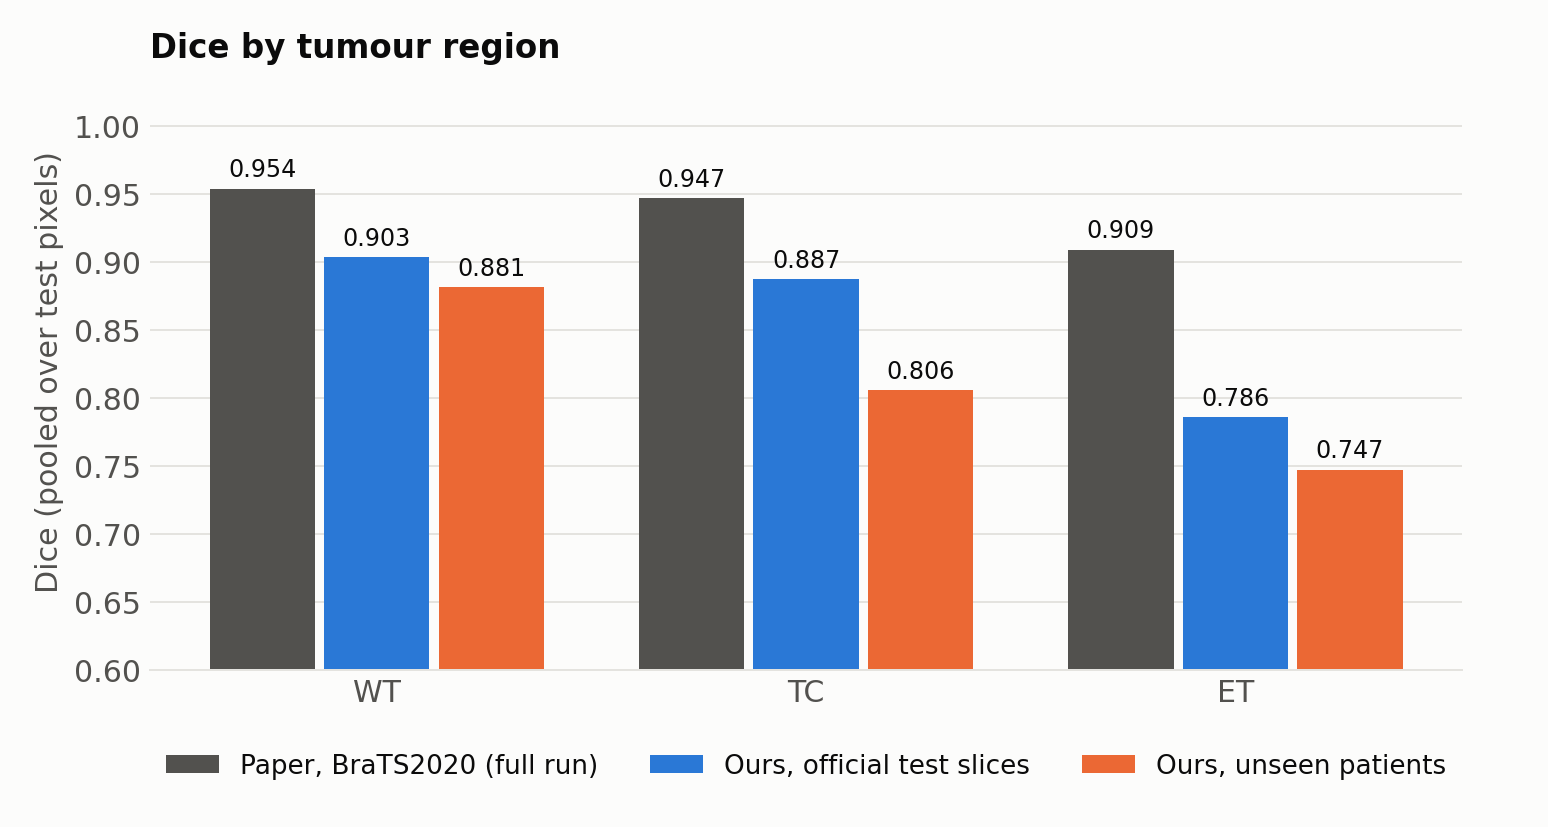

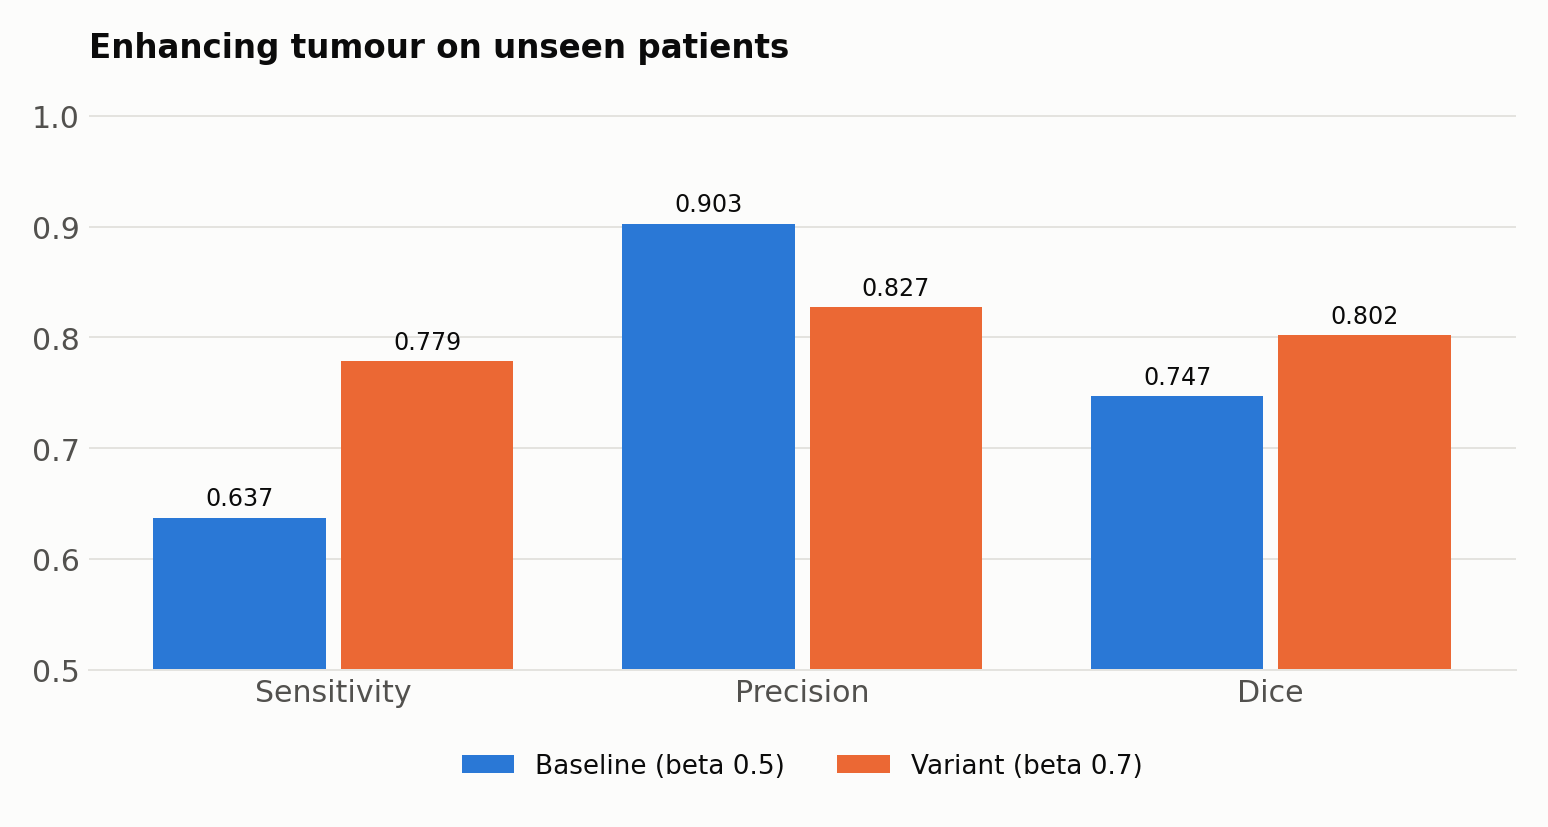

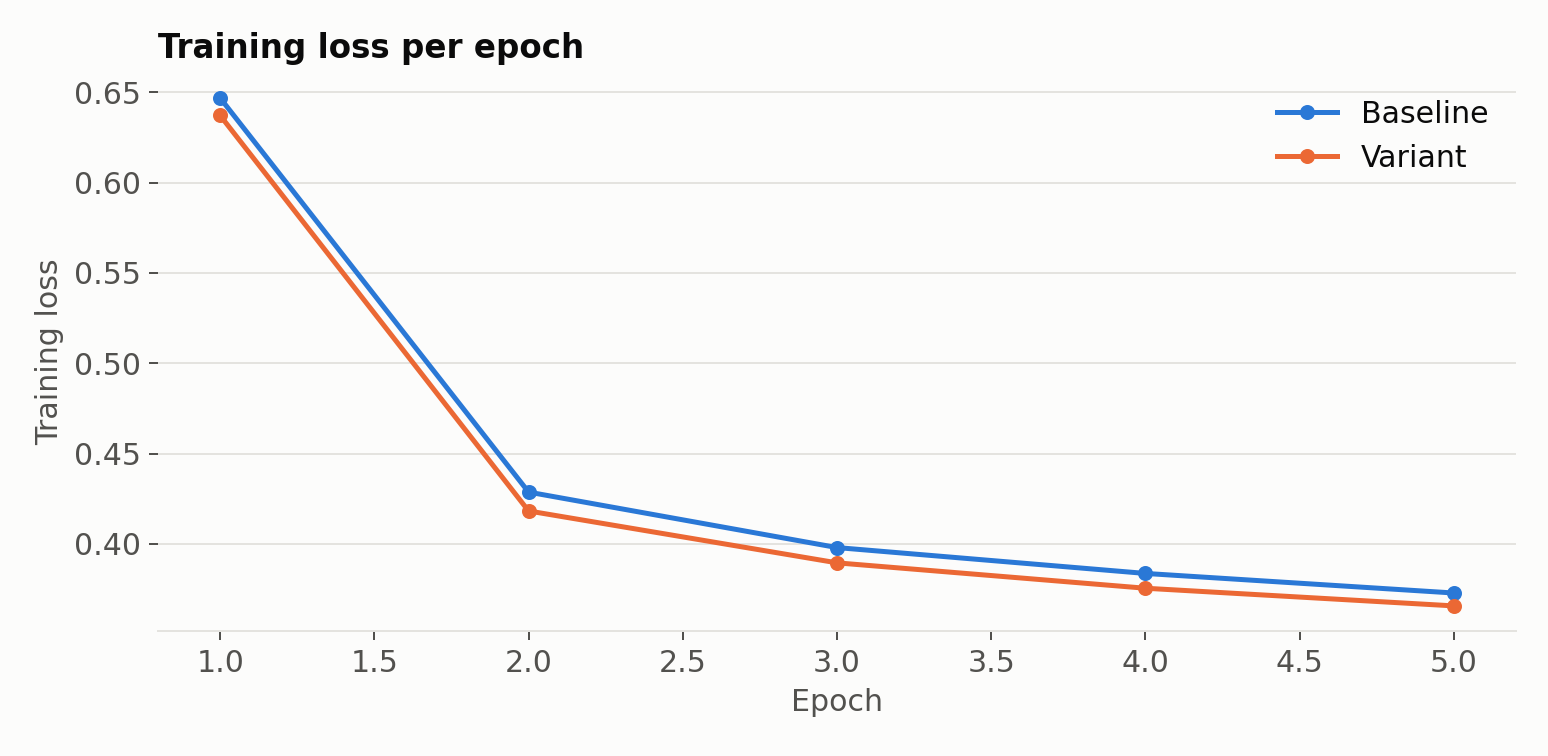

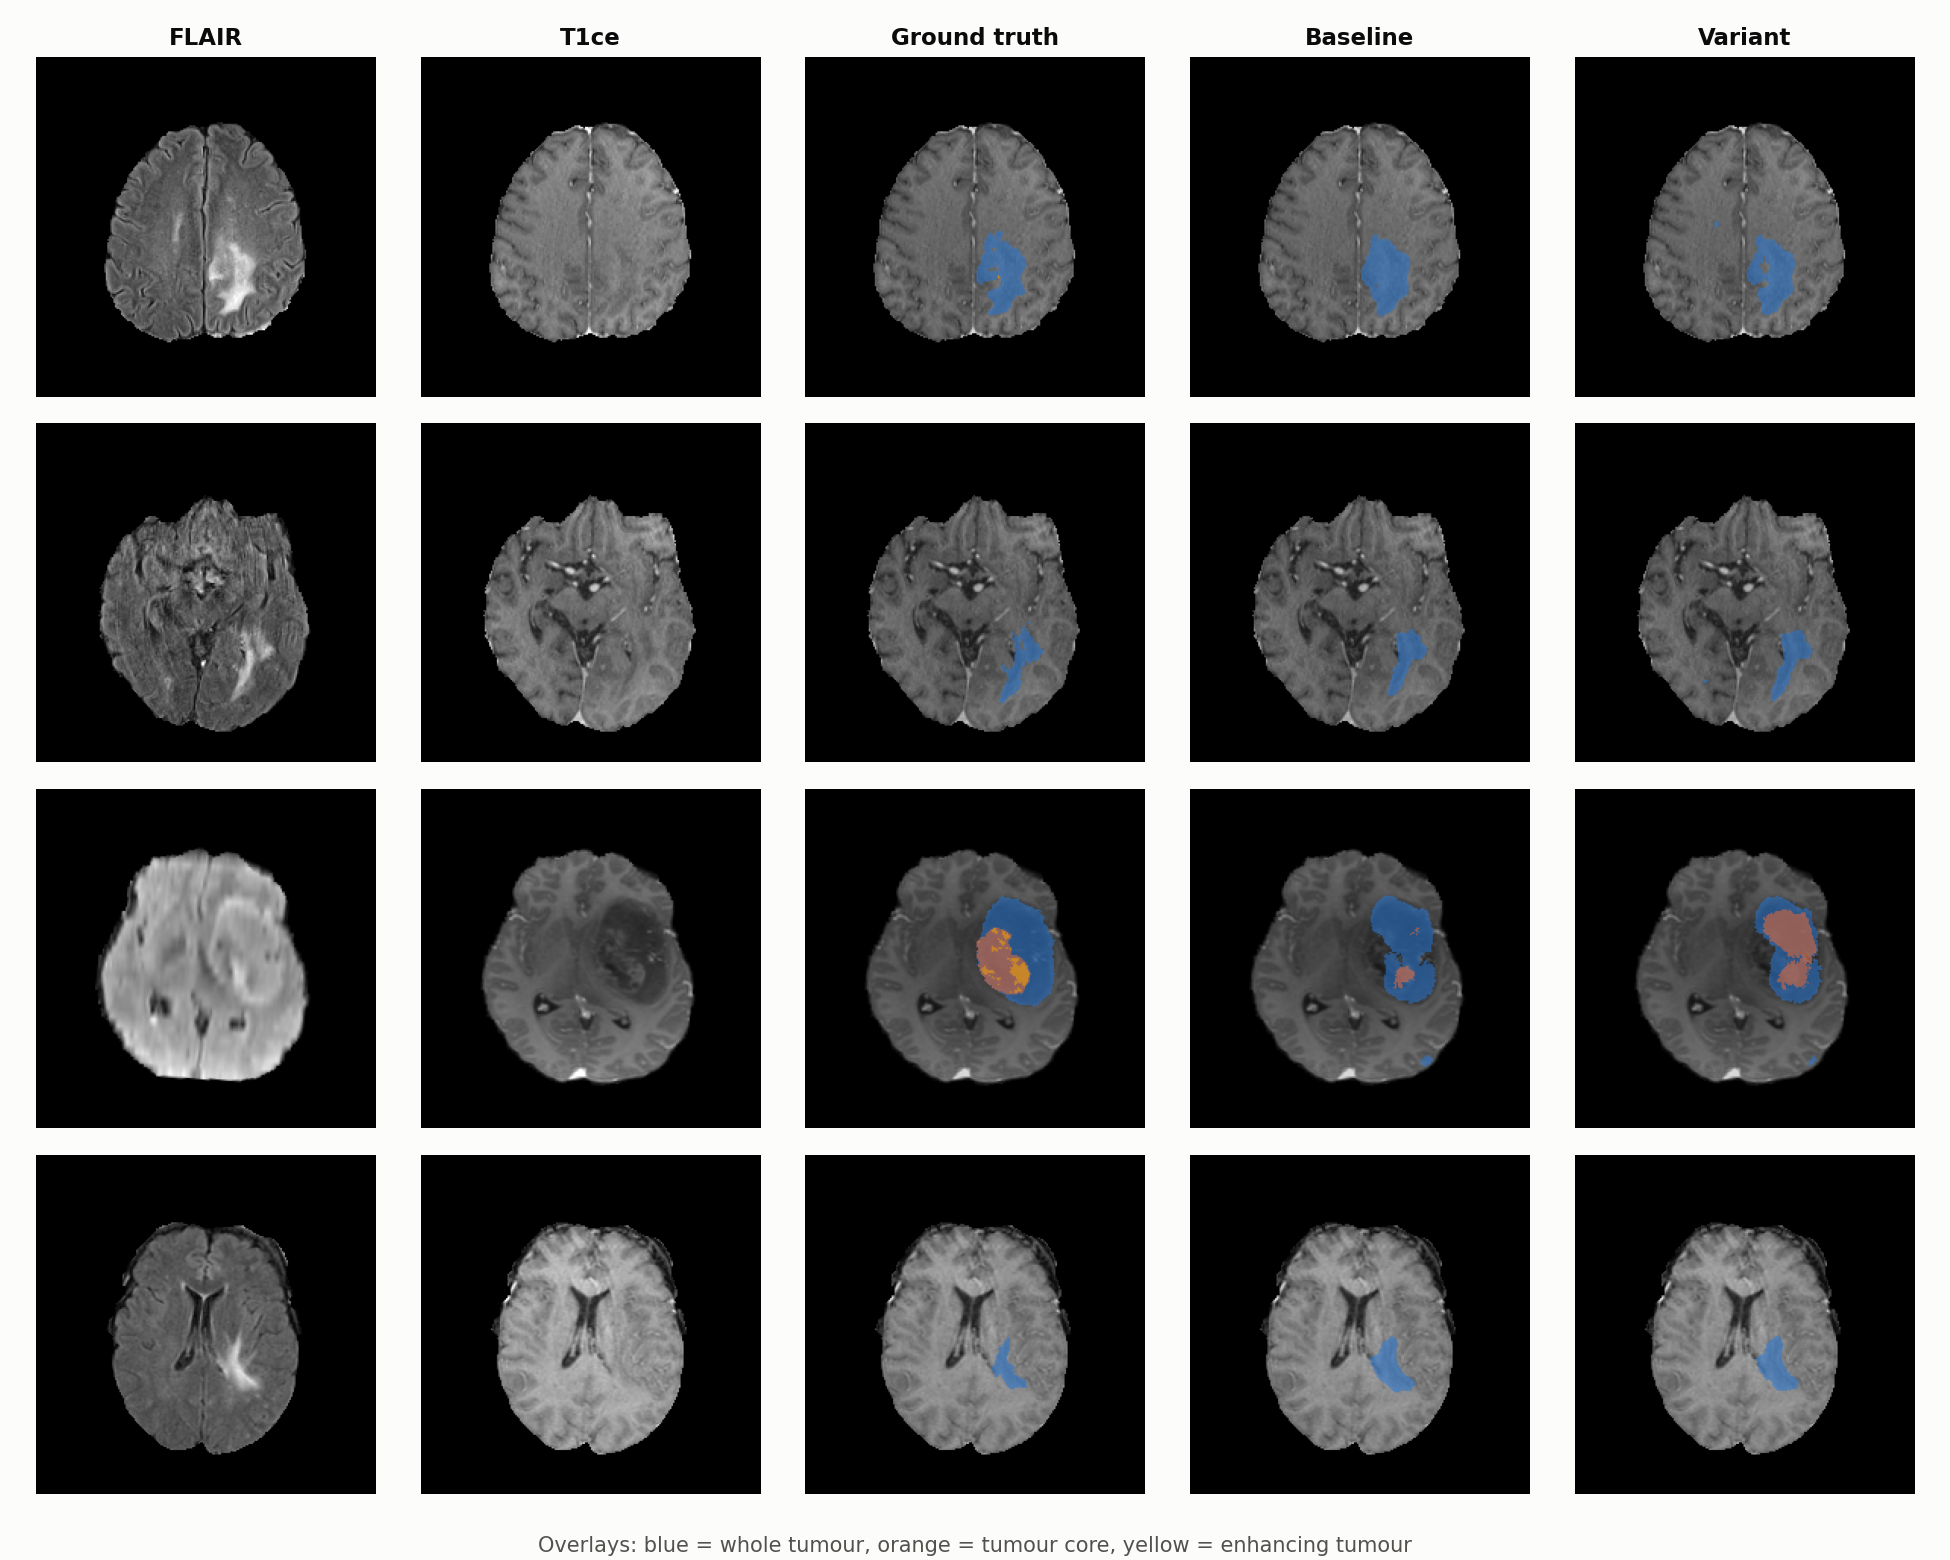

In [ ]:
!python -W ignore -m repro.make_report --baseline results/baseline --variant {VAR} --out results > /dev/null
from IPython.display import Markdown, Image, display
display(Markdown(open("results/summary.md").read()))
for f in ("dice_protocols", "et_variant", "training_loss", "examples"):
    if os.path.exists(f"results/figures/{f}.png"):
        display(Image(f"results/figures/{f}.png", width=760))

In [ ]:
# compact machine-readable dump of the numbers (for copying into the README / slides)
import json
for run in ("results/baseline", VAR):
    r = json.load(open(f"{run}/results.json"))
    keep = {k: r[k] for k in ("split", "test", "unseen", "device", "peak_gpu_mem_gb", "iters_per_epoch", "params_million") if k in r}
    keep["history"] = [{k: (round(v, 4) if isinstance(v, float) else v) for k, v in h.items()} for h in r["history"]]
    keep["config"] = {k: r["config"][k] for k in ("epochs", "batch_size", "n_subset", "n_heldout", "seed", "et_beta", "lr")}
    print("RESULT_JSON", run, json.dumps(keep, separators=(",", ":")))

RESULT_JSON results/baseline {"split":{"val":{"slices":543,"patients":80,"patients_also_in_train":80},"test":{"slices":520,"patients":79,"patients_also_in_train":79},"unseen":{"slices":1874,"patients":30,"patients_also_in_train":0},"train":{"slices":4348,"patients":80}},"test":{"n_slices":520,"n_patients":79,"WT":{"dice_pooled":0.9032865936312526,"sensitivity_pooled":0.9365281443984386,"specificity_pooled":0.9958899342747135,"hd95_official":2.811430451438685,"precision_pooled":0.8723239358897323,"dice_per_patient_mean":0.8879667981254773,"dice_per_patient_std":0.07428480271287144,"hd95_true_mean_px":13.748002951078785,"hd95_true_median_px":5.170555836978214,"hd95_true_n_slices":512,"hd95_undefined_slices":8},"TC":{"dice_pooled":0.8871446736184745,"sensitivity_pooled":0.9026397560621461,"specificity_pooled":0.9982306793329131,"hd95_official":1.9869791739317122,"precision_pooled":0.8721726027627891,"dice_per_patient_mean":0.7937688133095548,"dice_per_patient_std":0.24059268866415215,"hd9

In [ ]:
# download everything (results.json files, summary, figures, example arrays)
!cd /content/multiPI_TransBTS && zip -q -r /content/results.zip results
from google.colab import files
files.download("/content/results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>